In [84]:
import numpy as np
import pandas as pd

#전처리(인코딩)
from sklearn.preprocessing import LabelEncoder

#전처리(스케일링)
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import MaxAbsScaler

#데이터 나누기
from sklearn.model_selection import train_test_split

#학습모델
from sklearn.ensemble import RandomForestRegressor

#평가
from sklearn.metrics import root_mean_squared_error

In [85]:
train = pd.read_csv('flight_train.csv')
test = pd.read_csv('flight_test.csv')

print('train :', train.shape)
print('test :', test.shape)

train : (10505, 11)
test : (4502, 10)


In [86]:
set(train) - set(test)

{'price'}

<Axes: >

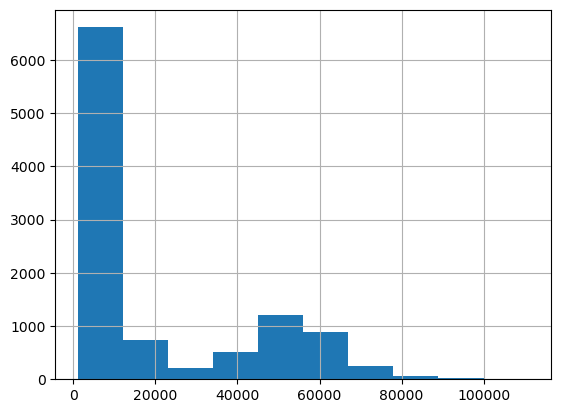

In [87]:
target = train.pop('price')
target.hist()

## 탐색적 데이터 분석

In [88]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10505 entries, 0 to 10504
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   airline           10505 non-null  object 
 1   flight            10505 non-null  object 
 2   source_city       10505 non-null  object 
 3   departure_time    10505 non-null  object 
 4   stops             10505 non-null  object 
 5   arrival_time      10505 non-null  object 
 6   destination_city  10505 non-null  object 
 7   class             10505 non-null  object 
 8   duration          10505 non-null  float64
 9   days_left         10505 non-null  int64  
dtypes: float64(1), int64(1), object(8)
memory usage: 820.8+ KB


In [89]:
train.head(3)

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left
0,Vistara,UK-776,Kolkata,Evening,one,Late_Night,Delhi,Economy,6.58,31
1,Vistara,UK-852,Bangalore,Morning,zero,Morning,Mumbai,Business,1.92,37
2,Indigo,6E-2348,Delhi,Evening,one,Late_Night,Bangalore,Economy,5.58,25


In [90]:
obj_cols = train.select_dtypes(include='O').columns

for col in obj_cols:
    is_same = False
    
    if set(train[col]) == set(test[col]):
        is_same = True
    
    print(col,":",is_same)

airline : True
flight : False
source_city : True
departure_time : True
stops : True
arrival_time : True
destination_city : True
class : True


In [91]:
train.isnull().sum()

airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
dtype: int64

In [92]:
test.isnull().sum()

airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
dtype: int64

In [93]:
train['flight'] = train['flight'].str.split('-').str[0]
test['flight'] = test['flight'].str.split('-').str[0]

### 인코딩(전처리)

In [94]:
train = pd.get_dummies(train)
test = pd.get_dummies(test)

print('train :', train.shape)
print('test :', test.shape)

train : (10505, 43)
test : (4502, 43)


### 데이터 나누기

In [95]:
x_train,x_val,y_train,y_val = train_test_split(
    train,
    target,
    test_size=0.2,
    random_state=0,
)

print('x_train :', x_train.shape)
print('x_val :', x_val.shape)
print('y_train :', y_train.shape)
print('y_val :', y_val.shape)

x_train : (8404, 43)
x_val : (2101, 43)
y_train : (8404,)
y_val : (2101,)


### 모델학습

In [96]:
model = RandomForestRegressor(random_state=0)
model.fit(x_train,y_train)

pred = model.predict(x_val)
pred

array([ 6147.36, 11884.58,  7231.28, ..., 47616.76,  4990.03, 44205.23])

### 모델평가

In [97]:
rmse = root_mean_squared_error(y_val,pred)
print("RMSE :", rmse)

RMSE : 4366.898025507842


## 성능개선

In [117]:
train = pd.read_csv('flight_train.csv')
test = pd.read_csv('flight_test.csv')

In [118]:
target = train.pop('price')

In [119]:
num_cols = train.select_dtypes(include='number').columns
num_cols

Index(['duration', 'days_left'], dtype='object')

In [121]:
train.head()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,f1,f2
0,Vistara,UK-776,Kolkata,Evening,one,Late_Night,Delhi,Economy,6.58,31,UK,776
1,Vistara,UK-852,Bangalore,Morning,zero,Morning,Mumbai,Business,1.92,37,UK,852
2,Indigo,6E-2348,Delhi,Evening,one,Late_Night,Bangalore,Economy,5.58,25,6E,2348
3,Air_India,AI-763,Kolkata,Early_Morning,one,Evening,Chennai,Business,12.00,15,AI,763
4,Indigo,6E-752,Hyderabad,Early_Morning,one,Evening,Chennai,Economy,9.50,20,6E,752


In [123]:
train['f1'] = train['flight'].str.split('-').str[0]
test['f1'] = test['flight'].str.split('-').str[0]

train['f2'] = train['flight'].str.split('-').str[1].astype(int)
test['f2'] = test['flight'].str.split('-').str[1].astype(int)

train = train.drop('flight', axis=1)
test = test.drop('flight', axis=1)

### 스케일링

In [124]:
scaler = StandardScaler()

train[num_cols] = scaler.fit_transform(train[num_cols])
test[num_cols] = scaler.transform(test[num_cols])

In [125]:
train = pd.get_dummies(train)
test = pd.get_dummies(test)

print('train :', train.shape)
print('test :', test.shape)

train : (10505, 44)
test : (4502, 44)


In [126]:
x_train,x_val,y_train,y_val = train_test_split(
    train,
    target,
    test_size=0.2,
    random_state=0,
)

print('x_train :', x_train.shape)
print('x_val :', x_val.shape)
print('y_train :', y_train.shape)
print('y_val :', y_val.shape)

x_train : (8404, 44)
x_val : (2101, 44)
y_train : (8404,)
y_val : (2101,)


In [127]:
model = RandomForestRegressor(max_depth=20, n_estimators=200, random_state=0)
model.fit(x_train,y_train)

pred = model.predict(x_val)
pred

array([ 6310.315     , 11902.95217817,  6710.86461706, ...,
       44425.19314144,  5568.42673788, 43994.71666667])

In [128]:
rmse = root_mean_squared_error(y_val,pred)
print("RMSE :", rmse)

RMSE : 3686.072670694012


In [129]:
submit = pd.DataFrame({'pred' : pred})
submit.to_csv('flight_result.csv', index=False)
submit.head()

,pred
0,6310.315000
1,11902.952178
2,6710.864617
3,37672.870000
4,52494.980948
